# Marker and peak-to-gene heatmaps

`epione.pl.marker_heatmap` and `epione.pl.peak2gene_heatmap` are line-by-line ports of
ArchR's `plotMarkerHeatmap` (`markerHeatmap`) and `plotPeak2GeneHeatmap`
(`peak2GeneHeatmap`). Everything ArchR computes before drawing — the `cutOff`
filter, log2 / row-z-score scaling, binary row sorting, `hclust` column order,
ComplexHeatmap's dendrogram reordering, `kmeans` link groups and the `nPlot`
subsampling — is reproduced, including R's random-number streams, so
`return_matrix=True` gives the same numbers as ArchR's `returnMatrix = TRUE`.

| ArchR | Epione |
|---|---|
| `getMarkerFeatures()` | `epi.tl.find_marker_features()` |
| `plotMarkerHeatmap(seMarker, cutOff, ...)` | `epi.pl.marker_heatmap(markers, cut_off, ...)` |
| `plotMarkerHeatmap(..., returnMatrix = TRUE)` | `epi.pl.marker_heatmap(..., return_matrix=True)` / `epi.pl.marker_heatmap_matrix()` |
| `addPeak2GeneLinks()` | `epi.tl.peak_to_gene()` |
| `plotPeak2GeneHeatmap(proj, k, nPlot, ...)` | `epi.pl.peak2gene_heatmap(**epi.pl.prepare_peak2gene_heatmap(...))` |
| `plotPeak2GeneHeatmap(..., returnMatrices = TRUE)` | `epi.pl.peak2gene_heatmap(..., return_matrices=True)` |

We use the ArchR hematopoiesis tutorial data (BMMC, CD34+ BMMC and PBMC; hg19),
preprocessed end to end with Epione. The last section summarises the recorded
parity of these functions against ArchR 1.0.3.

## Load the data

This tutorial runs on the ArchR Hematopoiesis dataset built **with Epione only** in
[`t_archr_heme_data`](t_archr_heme_data) (fragments from
`epi.datasets.archr_hematopoiesis`, QC, iterative LSI, Leiden clusters, UMAP,
gene scores, MACS3 peaks). Run that notebook once and point `EPIONE_ARCHR_HEME`
at its output directory. We read the gene-score and peak AnnData objects it writes.

In [1]:
import os, pathlib
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

import epione as epi

DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))
plt.rcParams['figure.dpi'] = 80

gs = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')
pk = ad.read_h5ad(DATA / 'heme_peaks.h5ad')
for a in (gs, pk):
    a.obs['log10_nFrags'] = np.log10(a.obs['n_fragment'].astype(float))
print(gs)
print(pk.shape, 'cells x peaks;', pk.obs['Clusters'].nunique(), 'clusters')

AnnData object with n_obs × n_vars = 10705 × 20057
    obs: 'Sample', 'n_fragment', 'tsse', 'Clusters', 'log10_nFrags'
    var: 'chrom', 'start', 'end', 'strand'
    uns: 'files'
    obsm: 'X_iterative_lsi', 'X_umap'
(10705, 232272) cells x peaks; 11 clusters


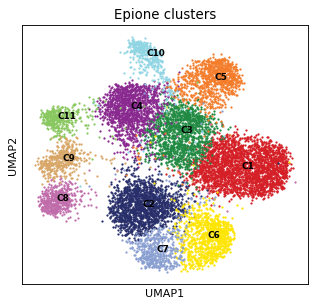

In [2]:
from epione.pl._marker_heatmap import palette_discrete
pal = palette_discrete(gs.obs['Clusters'])
fig, ax = plt.subplots(figsize=(4.6, 4.2))
for c, col in pal.items():
    m = (gs.obs['Clusters'] == c).to_numpy()
    ax.scatter(*gs.obsm['X_umap'][m].T, s=1, c=col, label=c, rasterized=True)
    ax.text(*np.median(gs.obsm['X_umap'][m], axis=0), c, fontsize=8, weight='bold')
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2')
ax.set_title('Epione clusters'); plt.show()

## Part 1 · Marker feature heatmap

`epi.tl.find_marker_features` tests each cluster against a bias-matched
background (TSS enrichment and log10 fragments, as in ArchR's
`getMarkerFeatures(bias = ...)`). `epi.pl.marker_heatmap` then takes the
long-form table directly; ArchR's assay names are available in `cut_off`
(`Mean`, `MeanBGD`, `Log2FC`, `FDR`, `Pval`), written with R syntax and R's NA
semantics.

In [3]:
%%time
markers_gs = epi.tl.find_marker_features(
    gs, group_by='Clusters', bias_vars=['tsse', 'log10_nFrags'], seed=1, verbose=False)
# strongest markers by Wilcoxon z (log2_fc alone favours features that are ~0 in the background)
markers_gs.sort_values('z', ascending=False).head()

CPU times: user 29.8 s, sys: 5.65 s, total: 35.5 s
Wall time: 35.5 s


,group,feature,mean_fg,mean_bg,pct_fg,pct_bg,log2_fc,U,z,p_value,fdr,n_fg,n_bg
26110,C2,BCL11B,4.169785,0.648052,0.680715,0.180237,2.685789,1537198.0,27.588142,0.0,0.0,1566,1265
14279,C1,RBM47,1.883891,0.618258,0.685000,0.295758,1.607432,2387942.0,24.802740,0.0,0.0,2000,1650
6001,C1,SLC24A4,1.652012,0.485278,0.612000,0.209697,1.767339,2352740.0,24.567415,0.0,0.0,2000,1650
11818,C1,SIRPA,1.596154,0.489024,0.672500,0.284848,1.706621,2370989.0,24.353741,0.0,0.0,2000,1650
2038,C1,NLRP3,1.875362,0.457330,0.609500,0.237576,2.035858,2347778.0,24.234934,0.0,0.0,2000,1650


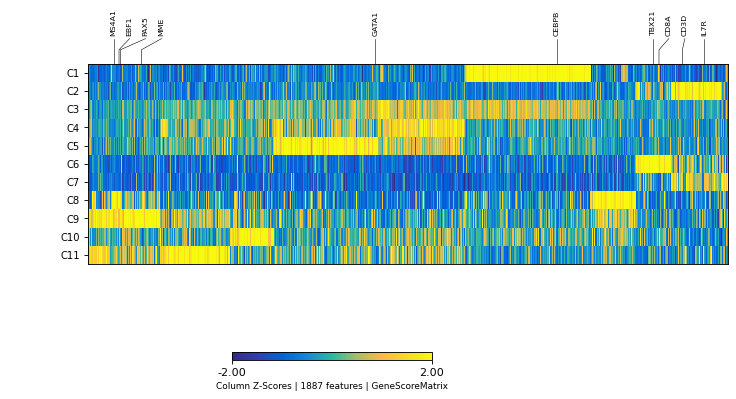

In [4]:
marker_genes = ['CD34', 'GATA1', 'PAX5', 'MS4A1', 'EBF1', 'MME', 'CD14', 'CEBPB', 'MPO',
                'IRF8', 'CD3D', 'CD8A', 'TBX21', 'IL7R']
fig, res = epi.pl.marker_heatmap(
    markers_gs, cut_off='FDR <= 0.01 & Log2FC >= 1.25',
    label_markers=marker_genes, transpose=True, use_matrix='GeneScoreMatrix',
    figsize=(10, 5), show=False)
plt.show()

`return_matrix=True` returns exactly the matrix ArchR draws (rows = features in
binary-sorted order, columns = clusters; the transposed version when
`transpose=True`). `marker_heatmap_matrix` also exposes the display order,
the `cut_off` pass matrix and the labels.

In [5]:
mat = epi.pl.marker_heatmap(markers_gs, cut_off='FDR <= 0.01 & Log2FC >= 1.25',
                            use_matrix='GeneScoreMatrix', return_matrix=True)
print(mat.shape)
res = epi.pl.marker_heatmap_matrix(markers_gs, cut_off='FDR <= 0.01 & Log2FC >= 1.25',
                                   use_matrix='GeneScoreMatrix')
print('cluster order (hclust):', list(mat.columns[res.col_order]))
mat.round(2).head()

(1887, 11)


cluster order (hclust): ['C9', 'C11', 'C10', 'C5', 'C3', 'C4', 'C1', 'C8', 'C6', 'C2', 'C7']


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
LRRC26,-0.87,-0.82,-0.05,0.72,-0.25,-0.92,-0.92,-0.85,1.81,1.08,1.07
TCL1A,-0.77,-0.53,-0.46,-0.56,-0.52,-0.80,-0.67,1.54,2.00,0.19,0.39
DNTT,-0.62,-0.68,-0.03,0.01,-0.33,-1.26,-1.19,0.41,2.00,0.59,0.98
TNFRSF13B,-0.88,-0.88,-0.23,-0.20,-0.25,-1.07,-1.00,0.32,1.37,1.75,1.06
SLC35G4,-0.35,-0.49,-0.45,-0.02,0.42,-1.41,-1.04,-0.72,1.63,1.09,1.34


Peak markers work the same way. ArchR uses the `solarExtra` palette for
non-gene-score matrices.

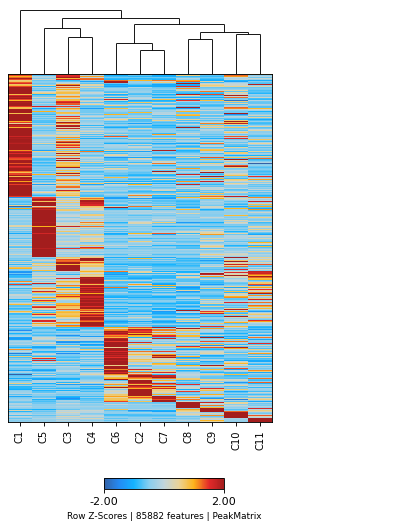

85882 marker peaks
CPU times: user 4min 29s, sys: 49.2 s, total: 5min 18s
Wall time: 5min 18s


In [6]:
%%time
markers_pk = epi.tl.find_marker_features(
    pk, group_by='Clusters', bias_vars=['tsse', 'log10_nFrags'], seed=1, verbose=False)
fig, res_pk = epi.pl.marker_heatmap(markers_pk, cut_off='FDR <= 0.1 & Log2FC >= 0.5',
                                    use_matrix='PeakMatrix', n_label=0, figsize=(6, 7), show=False)
plt.show()
print(res_pk.matrix.shape[0], 'marker peaks')

## Part 2 · Peak-to-gene heatmap

`epi.tl.peak_to_gene` links peaks to genes (gene scores here, as in ArchR's
`addPeak2GeneLinks(useMatrix = "GeneScoreMatrix")`) over 500 kNN metacells.
`epi.pl.prepare_peak2gene_heatmap` rebuilds ArchR's heatmap inputs from that run:
the same metacells, log2-normalised to 10⁴, and the `VarQATAC` / `VarQRNA`
variance quantiles. The heatmap keeps links with r ≥ 0.45, FDR ≤ 1e-4 and both
variance quantiles above 0.25. It groups them into `k = 25` kmeans clusters and
shows at most `nPlot = 25,000`.

In [7]:
%%time
gene_ann = pd.DataFrame({'gene_name': gs.var_names, 'chrom': gs.var['chrom'].values,
                         'start': gs.var['start'].values, 'end': gs.var['end'].values,
                         'strand': gs.var['strand'].values})
links = epi.tl.peak_to_gene(pk, rna=gs, gene_annotation=gene_ann, use_rep='X_iterative_lsi',
                            n_metacells=500, k_neighbors=100, max_distance=250_000,
                            seed=1, verbose=False)
prep = epi.pl.prepare_peak2gene_heatmap(pk, gs, links=links)
print(f'{len(links):,} peak-gene pairs tested')

1,493,249 peak-gene pairs tested
CPU times: user 25.1 s, sys: 4.97 s, total: 30.1 s
Wall time: 29.4 s


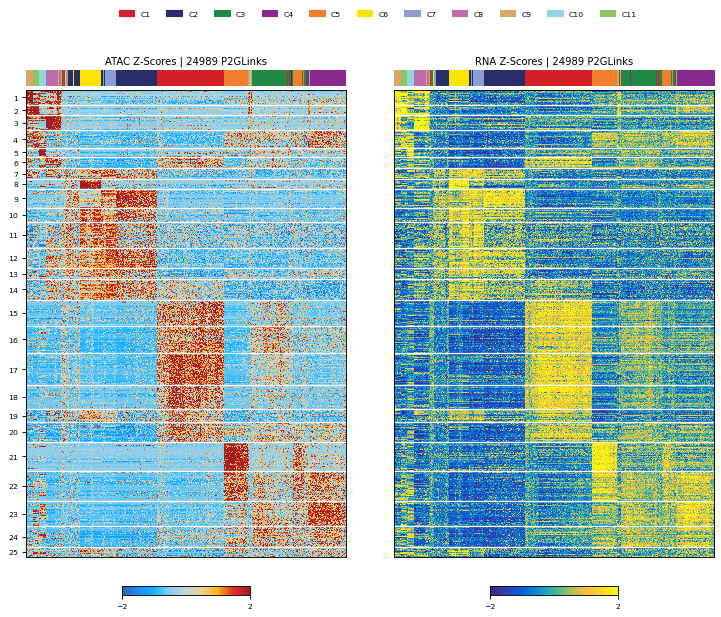

24989 links shown in 25 kmeans groups
CPU times: user 5.38 s, sys: 1.97 s, total: 7.35 s
Wall time: 7.34 s


In [8]:
%%time
fig, p2g = epi.pl.peak2gene_heatmap(**prep, cell_groups=pk.obs['Clusters'].to_numpy(),
                                    k=25, n_plot=25_000, seed=1, figsize=(10, 8), show=False)
plt.show()
print(p2g.atac.shape[0], 'links shown in', len(np.unique(p2g.kmeans_id)), 'kmeans groups')

In [9]:
# Genes behind each kmeans block (top 5 by number of links)
blk = p2g.links.assign(kmeans=p2g.kmeans_id)
blk.groupby('kmeans')['gene'].agg(lambda g: ', '.join(g.value_counts().index[:5])).head(10)

kmeans
1            VPREB1, IGLL5, GGTLC2, ZNF280B, DTX1
2     BTBD6, ENSG00000204003, HS1BP3, LCN6, TCL1B
3            ZNF608, ZCCHC7, PLEKHG1, GRHPR, CCR6
4           IGLL1, PALD1, MYO7A, CCDC188, ZDHHC22
5                SMPD3, PRMT7, PTPRS, LAMP5, KRT5
6             TCOF1, CD74, MEF2C, CHST15, HLA-DMB
7         ZBP1, APOBEC3H, APOBEC3G, HIVEP2, CXCR4
8              RUNX3, NFATC2, LRRC46, KLRD1, CCL5
9                  BCL11B, LEF1, IL7R, CD5, GRAP2
10               FYN, BCL11B, RUNX3, PRKCH, IKZF3
Name: gene, dtype: object

## Part 3 · Parity vs ArchR

Both functions were validated against ArchR 1.0.3 on ArchR's own Hematopoiesis
project (10,660 cells, 11 clusters). To isolate the heatmap step, ArchR's
`getMarkerFeatures` statistics and `addPeak2GeneLinks` links were fed to Epione
unchanged, and each output was compared element-wise. The ArchR reference outputs
are generated outside this repository; the gates were registered before any
comparison in `tests/parity/marker_heatmap/MANIFEST.md`, and
`tests/test_marker_heatmap.py` re-checks them when `EPIONE_ARCHR_PARITY_DIR`
points at the reference outputs.

| Output | Class | Metric | Gate | Result |
|---|---|---|---|---|
| `marker_heatmap(return_matrix=True)`, 9 configurations¹ | 1 deterministic | max abs error | ≤ 1e-8 | **0.0** (bit-identical) |
| Row / column names, NaN pattern | 1 | equality | identical | identical (9/9) |
| Drawn row / column order (ward.D2 + dendrogram reordering) | 1 | equality | identical | identical (9/9) |
| Row labels and their positions | 1 | equality | identical | identical (9/9) |
| Peak-to-gene ATAC / RNA matrices, R kmeans injected (2 configs²) | 1 deterministic | max abs error | ≤ 1e-8 | **0.0** |
| kmeans ids, column order, groups, link rows, subsampled rows | 1 | equality | identical | identical |
| Free-running kmeans (Python Hartigan-Wong + R RNG) | 3 clustering | ARI | ≥ 0.95 | **1.0** (labels identical) |

¹ transpose, invert, `plotLog2FC`, `binaryClusterRows = FALSE`, `subsetMarkers`,
`clusterCols = FALSE`, `scaleRows = FALSE`, `log2Norm = FALSE`, and `abs()` / `!`
cut-offs. ² `k = 25, nPlot = 25000, seed = 1` (66k links, subsampling path) and
`k = 12, nPlot = 4000, seed = 7`.

Exactness required porting R's arithmetic: `rowMeans`/`colSums` accumulate in
long double, `matrixStats::rowVars` uses a refinement pass, `log2` comes from libm,
and ArchR sessions run `RNGkind("L'Ecuyer-CMRG")` after `addArchRThreads(threads > 1)`,
which is why `peak2gene_heatmap` defaults to `rng_kind="L'Ecuyer-CMRG"`.

When Epione computes the upstream statistics itself (as in Parts 1 and 2 above),
the heatmap inputs differ from ArchR's because `find_marker_features` and
`peak_to_gene` are separate implementations. On ArchR's project these numbers were
reported, not gated: gene-score Log2FC Spearman 0.79, heatmap marker-set Jaccard
0.48, peak-gene correlation Spearman 0.89 on 1.1 M shared pairs.

## Notes

* `cut_off` takes R syntax: `&`, `|`, `!`, comparisons, `abs()`, `log2()`,
  etc. It uses R's NA logic (`NA & FALSE` is `FALSE`), so rows with NA statistics
  are kept or dropped exactly as in ArchR.
* `subset_markers` uses 1-based row indices, as in R.
* `peak2gene_heatmap(rng_kind="Mersenne-Twister")` matches an R session that never
  called `addArchRThreads(threads > 1)`.
* ArchR quirk reproduced: with `grep_exclude`, the default labels are taken from
  rows *before* exclusion (as in `plotMarkerHeatmap`).